In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ---- CONFIG ----
DATA_PATH   = "Turbine_Data_Kelmarsh_2_2017.csv"   # upload to Colab or mount Drive and edit path
RANDOM_SEED = 42
RATED_KW    = 2050.0
CUT_OUT_MS  = 25.0
BIN_W       = 0.5      # m/s, bin width for binned median
MIN_N       = 30       # min clean rows per bin to call a bin "reliable"
K_MAD       = 3.0      # abnormal if power < median - K_MAD * sigma
MIN_SIGMA_KW = 0.02 * RATED_KW   # sigma floor, avoids flagging normal scatter on the plateau
SMOOTH_W_MS = 0.5      # smoothing window for the ML curve

COL_WS   = "Wind speed (m/s)"
COL_P    = "Power (kW)"
COL_PC   = "Potential power default PC (kW)"
COL_LOST = "Lost Production to Downtime (kWh)"

np.random.seed(RANDOM_SEED)

# Optional: upload from your computer
# from google.colab import files; files.upload()

In [ ]:
need = [COL_WS, COL_P, COL_PC, COL_LOST]

# read header only (line 10, after 9 comment lines)
hdr = pd.read_csv(DATA_PATH, skiprows=9, nrows=0).columns
ts_col = hdr[0]
missing = [c for c in need if c not in hdr]
assert not missing, f"Missing columns: {missing}"

raw = pd.read_csv(DATA_PATH, skiprows=9, usecols=[ts_col] + need, low_memory=False)

# fix '# ' prefix on first column name and parse timestamp
print("Original first column name:", repr(ts_col))
raw = raw.rename(columns={ts_col: "timestamp"})
raw["timestamp"] = pd.to_datetime(raw["timestamp"])

print("Shape:", raw.shape)
print(raw.dtypes)
print(raw.head(3))

Original first column name: '# Date and time'
Shape: (52560, 5)
timestamp                            datetime64[ns]
Wind speed (m/s)                            float64
Lost Production to Downtime (kWh)           float64
Power (kW)                                  float64
Potential power default PC (kW)             float64
dtype: object
            timestamp  Wind speed (m/s)  Lost Production to Downtime (kWh)  \
0 2017-01-01 00:00:00          7.620052                                0.0   
1 2017-01-01 00:10:00          8.035563                                0.0   
2 2017-01-01 00:20:00          7.602766                                0.0   

    Power (kW)  Potential power default PC (kW)  
0   916.475342                       852.097322  
1  1136.349487                       993.083134  
2   892.446960                       846.323697  


In [ ]:
# --- cut-in from the theoretical curve (first wind speed with PC > 0) ---
cut_in = raw.loc[raw[COL_PC] > 0, COL_WS].min()
print(f"Cut-in (from theoretical curve): {cut_in:.2f} m/s")

df = raw.copy()
log = []

def step(name, remove_mask):
    """Remove rows where mask is True and print how many were removed."""
    global df
    n = int(remove_mask.sum())
    df = df.loc[~remove_mask].copy()
    log.append((name, n, len(df)))
    print(f"{name:60s} removed={n:6d}  remaining={len(df):6d}")

print(f"{'Start':60s} rows={len(df)}")

# Step 1: NaN in wind speed or power
step("1) NaN in wind speed or power",
     df[COL_WS].isna() | df[COL_P].isna())

# Step 2: downtime flag
print("   (NaN in Lost Production col, treated as not flagged:", int(df[COL_LOST].isna().sum()), ")")
step("2) Lost Production to Downtime > 0", df[COL_LOST] > 0)

# Step 3: abnormal rows, per-bin median and MAD rule (lower side only)
#   sigma = max(1.4826 * MAD, MIN_SIGMA_KW);  flag if power < median - K_MAD*sigma
#   - robust to outliers (median/MAD, not mean/std)
#   - bins with < MIN_N rows are NOT judged (too few points for stats) -> reported below
#   - upper side is NOT removed (overproduction up to ~2080 kW is capped later)
p_nn   = df[COL_P].clip(lower=0)               # negatives treated as 0 only for this statistic
bin_id = (df[COL_WS] // BIN_W) * BIN_W
grp    = p_nn.groupby(bin_id)
med    = grp.transform("median")
cnt    = grp.transform("size")
mad    = (p_nn - med).abs().groupby(bin_id).transform("median")
sigma  = np.maximum(1.4826 * mad, MIN_SIGMA_KW)
resid  = p_nn - med

low_flag   = (cnt >= MIN_N) & (resid < -K_MAD * sigma)
high_info  = (cnt >= MIN_N) & (resid >  K_MAD * sigma)
print(f"   (info) rows in bins with n<{MIN_N}, not judged by MAD rule: {int((cnt < MIN_N).sum())}")
print(f"   (info) rows far ABOVE median (kept): {int(high_info.sum())}")
step(f"3) Abnormal low power (< median - {K_MAD}*sigma per {BIN_W} m/s bin)", low_flag)

# Step 4: negative power -> clip to 0 (not removed; small negatives = turbine self-consumption)
neg = df[COL_P] < 0
print(f"4) Negative power rows remaining: {int(neg.sum())} "
      f"(of which at wind >= cut-in: {int((neg & (df[COL_WS] >= cut_in)).sum())})")
df["power_clean"] = df[COL_P].clip(lower=0)
print(f"{'4) Negative power clipped to 0 (no rows removed)':60s} removed=     0  remaining={len(df):6d}")

print("\nSummary:")
print(pd.DataFrame(log, columns=["step", "removed", "remaining"]).to_string(index=False))
print("\nCleaned describe:\n", df[[COL_WS, "power_clean"]].describe())

Cut-in (from theoretical curve): 3.00 m/s
Start                                                        rows=52560
1) NaN in wind speed or power                                removed=   515  remaining= 52045
   (NaN in Lost Production col, treated as not flagged: 0 )
2) Lost Production to Downtime > 0                           removed=   357  remaining= 51688
   (info) rows in bins with n<30, not judged by MAD rule: 50
   (info) rows far ABOVE median (kept): 359
3) Abnormal low power (< median - 3.0*sigma per 0.5 m/s bin) removed=    80  remaining= 51608
4) Negative power rows remaining: 3560 (of which at wind >= cut-in: 65)
4) Negative power clipped to 0 (no rows removed)             removed=     0  remaining= 51608

Summary:
                                                        step  removed  remaining
                               1) NaN in wind speed or power      515      52045
                          2) Lost Production to Downtime > 0      357      51688
3) Abnormal low powe

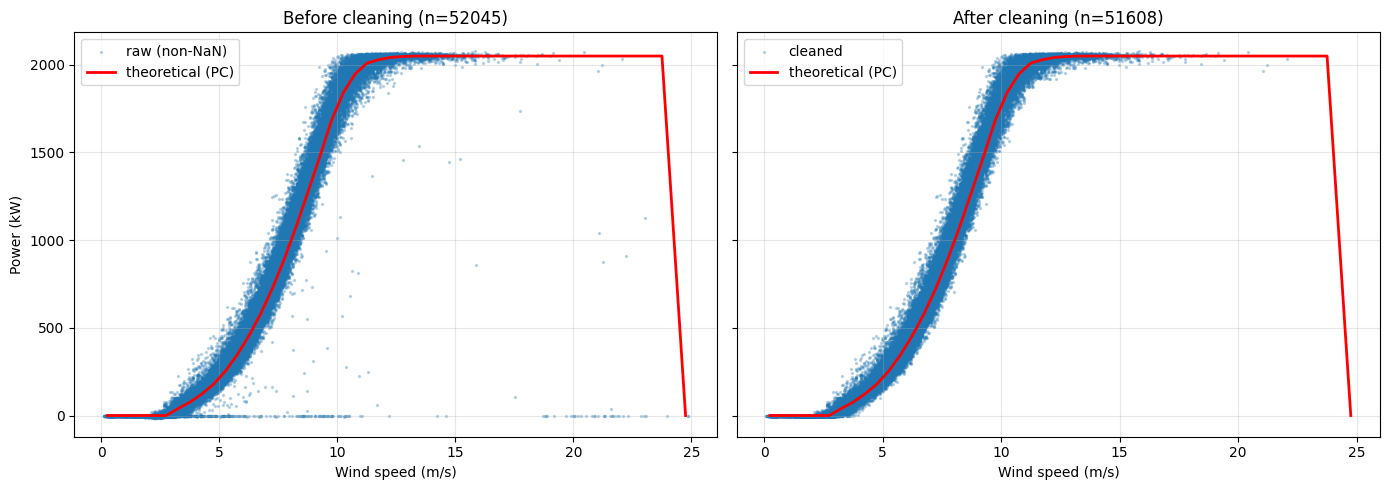

v_switch (upper edge of last reliable bin, n >= 30): 16.0 m/s

Clean row count per bin for wind >= 12 m/s:
wbin
12.0    404
12.5    270
13.0    215
13.5    180
14.0     94
14.5     55
15.0     42
15.5     30
16.0     15
16.5      9
17.0      6
17.5      7
18.0      3
18.5      3
19.0      3
19.5      0
20.0      1
20.5      0
21.0      2
21.5      0
22.0      1
22.5      0
23.0      0
23.5      0
24.0      0
24.5      0


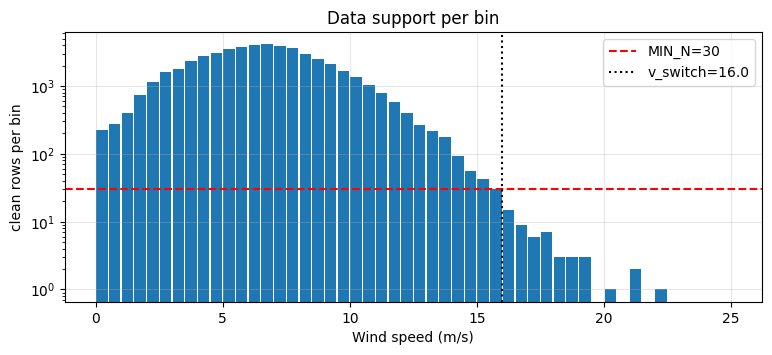

In [ ]:
# theoretical curve as binned median of the PC column
b_raw = (raw[COL_WS] // BIN_W) * BIN_W
theo = raw.groupby(b_raw)[COL_PC].median()
theo_x = theo.index.values + BIN_W / 2

# scatter before / after
before = raw.dropna(subset=[COL_WS, COL_P])
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
ax[0].scatter(before[COL_WS], before[COL_P], s=2, alpha=0.25, label="raw (non-NaN)")
ax[0].plot(theo_x, theo.values, "r-", lw=2, label="theoretical (PC)")
ax[0].set_title(f"Before cleaning (n={len(before)})")
ax[1].scatter(df[COL_WS], df["power_clean"], s=2, alpha=0.25, label="cleaned")
ax[1].plot(theo_x, theo.values, "r-", lw=2, label="theoretical (PC)")
ax[1].set_title(f"After cleaning (n={len(df)})")
for a in ax:
    a.set_xlabel("Wind speed (m/s)"); a.grid(alpha=0.3); a.legend()
ax[0].set_ylabel("Power (kW)")
plt.tight_layout(); plt.show()

# binned median baseline on cleaned data
df["wbin"] = (df[COL_WS] // BIN_W) * BIN_W
bm = df.groupby("wbin")["power_clean"].agg(median="median", n="size")
bm["center"] = bm.index + BIN_W / 2

# reliable range: walk up from cut-in, stop at first bin with n < MIN_N (or a gap)
grid_bins = np.arange(0, CUT_OUT_MS, BIN_W)
counts = bm["n"].reindex(grid_bins).fillna(0).astype(int)
v_switch = None
for s, c in counts.items():
    if s + BIN_W <= cut_in:
        continue
    if c < MIN_N:
        break
    v_switch = s + BIN_W
print(f"v_switch (upper edge of last reliable bin, n >= {MIN_N}): {v_switch} m/s")
print("\nClean row count per bin for wind >= 12 m/s:")
print(counts[counts.index >= 12].to_string())

plt.figure(figsize=(9, 3.5))
plt.bar(counts.index + BIN_W / 2, counts.values, width=BIN_W * 0.9)
plt.axhline(MIN_N, color="r", ls="--", label=f"MIN_N={MIN_N}")
plt.axvline(v_switch, color="k", ls=":", label=f"v_switch={v_switch}")
plt.yscale("log"); plt.xlabel("Wind speed (m/s)"); plt.ylabel("clean rows per bin")
plt.legend(); plt.grid(alpha=0.3); plt.title("Data support per bin"); plt.show()

Weeks total=53, test weeks=11
Train rows=40745 (max ws 22.05), Test rows=10863 (max ws 18.61)
            model  RMSE_train  R2_train  RMSE_test  R2_test
HGB unconstrained     66.4877    0.9881    74.0271   0.9881
    HGB monotonic     66.5030    0.9881    73.9697   0.9881
HGB unconstrained: distinct fine-grid values=171, max single jump=62.03 kW, non-monotone steps=10
HGB monotonic: distinct fine-grid values=163, max single jump=57.64 kW, non-monotone steps=0

ML(smoothed) vs binned median on reliable bins: mean abs diff=4.4 kW, max abs diff=15.1 kW


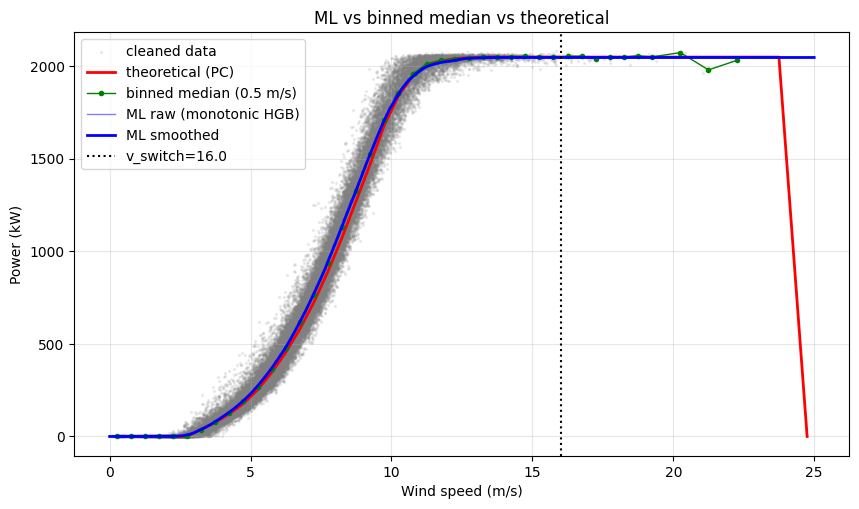

In [ ]:
# --- block split by week (see reasoning above) ---
blk = ((df["timestamp"] - df["timestamp"].min()).dt.days // 7).values
rng = np.random.default_rng(RANDOM_SEED)
blocks = np.unique(blk)
test_blocks = rng.choice(blocks, size=int(round(0.2 * len(blocks))), replace=False)
is_test = np.isin(blk, test_blocks)

X = df[[COL_WS]].values
y = df["power_clean"].values
Xtr, ytr, Xte, yte = X[~is_test], y[~is_test], X[is_test], y[is_test]
print(f"Weeks total={len(blocks)}, test weeks={len(test_blocks)}")
print(f"Train rows={len(Xtr)} (max ws {Xtr.max():.2f}), Test rows={len(Xte)} (max ws {Xte.max():.2f})")

def make_model(mono):
    return HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=50,
        monotonic_cst=[1] if mono else None,
        early_stopping=False, random_state=RANDOM_SEED)

def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))

models, rows = {}, []
for name, mono in [("HGB unconstrained", False), ("HGB monotonic", True)]:
    m = make_model(mono).fit(Xtr, ytr)
    models[name] = m
    rows.append([name, rmse(ytr, m.predict(Xtr)), r2_score(ytr, m.predict(Xtr)),
                 rmse(yte, m.predict(Xte)), r2_score(yte, m.predict(Xte))])
print(pd.DataFrame(rows, columns=["model", "RMSE_train", "R2_train", "RMSE_test", "R2_test"]).round(4).to_string(index=False))

# --- raggedness check + smoothing on a fine grid ---
FINE_STEP = 0.05
fine = np.arange(0, CUT_OUT_MS + 1e-9, FINE_STEP)
final_model = models["HGB monotonic"]          # chosen: monotonic (physically sensible)
for name, m in models.items():
    pf = m.predict(fine.reshape(-1, 1))
    print(f"{name}: distinct fine-grid values={len(np.unique(np.round(pf, 6)))}, "
          f"max single jump={np.abs(np.diff(pf)).max():.2f} kW, "
          f"non-monotone steps={int((np.diff(pf) < -1e-9).sum())}")

pred_fine = final_model.predict(fine.reshape(-1, 1))
win = int(round(SMOOTH_W_MS / FINE_STEP)) | 1   # odd window
smooth = pd.Series(pred_fine).rolling(win, center=True, min_periods=1).mean().values
smooth = np.maximum.accumulate(smooth)           # enforce non-decreasing after smoothing

# --- ML vs binned median comparison (decision 3) ---
ml_at_bins = np.interp(bm["center"].values, fine, smooth)
rel = bm["n"].values >= MIN_N
diff = ml_at_bins[rel] - bm["median"].values[rel]
print(f"\nML(smoothed) vs binned median on reliable bins: "
      f"mean abs diff={np.abs(diff).mean():.1f} kW, max abs diff={np.abs(diff).max():.1f} kW")

plt.figure(figsize=(10, 5.5))
plt.scatter(df[COL_WS], df["power_clean"], s=2, alpha=0.12, color="gray", label="cleaned data")
plt.plot(theo_x, theo.values, "r-", lw=2, label="theoretical (PC)")
plt.plot(bm["center"], bm["median"], "go-", ms=3, lw=1, label=f"binned median ({BIN_W} m/s)")
plt.plot(fine, pred_fine, "b-", lw=1, alpha=0.5, label="ML raw (monotonic HGB)")
plt.plot(fine, smooth, "b-", lw=2, label="ML smoothed")
plt.axvline(v_switch, color="k", ls=":", label=f"v_switch={v_switch}")
plt.xlabel("Wind speed (m/s)"); plt.ylabel("Power (kW)"); plt.grid(alpha=0.3); plt.legend()
plt.title("ML vs binned median vs theoretical"); plt.show()

Max ML prediction below cut-in (3.00 m/s): 20.44 kW (forced to 0)
 wind_speed_ms  power_kw
           0.0      0.00
           0.5      0.00
           1.0      0.00
           1.5      0.00
           2.0      0.00
           2.5      0.00
           3.0      0.00
           3.5     57.58
           4.0    105.29
           4.5    161.31
           5.0    230.82
           5.5    319.57
           6.0    424.09
           6.5    548.43
           7.0    693.14
           7.5    856.51
           8.0   1039.76
           8.5   1235.78
           9.0   1431.10
           9.5   1622.01
          10.0   1786.20
          10.5   1902.44
          11.0   1974.32
          11.5   2011.00
          12.0   2026.55
          12.5   2038.85
          13.0   2045.33
          13.5   2047.74
          14.0   2047.95
          14.5   2047.95
          15.0   2047.95
          15.5   2047.95
          16.0   2047.95
          16.5   2050.00
          17.0   2050.00
          17.5   2050.00
         

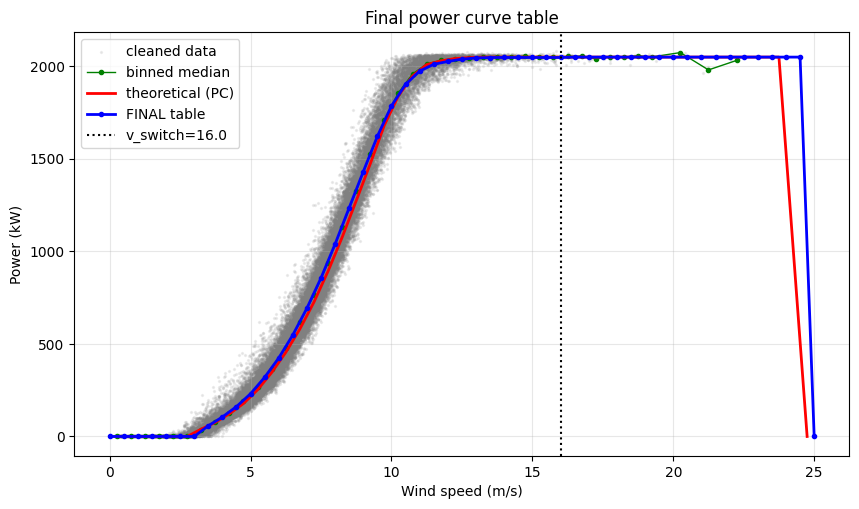

In [ ]:
grid = np.arange(0, CUT_OUT_MS + 1e-9, 0.5)
ml = np.interp(grid, fine, smooth)

print(f"Max ML prediction below cut-in ({cut_in:.2f} m/s): {ml[grid < cut_in].max():.2f} kW (forced to 0)")

p = np.clip(ml, 0, RATED_KW)            # rule 2: cap at rated, clip negatives
p[grid < cut_in] = 0.0                  # below cut-in -> 0
p[grid > v_switch] = RATED_KW           # rule 1: plateau above reliable range
p[grid >= CUT_OUT_MS] = 0.0             # rule 1: cut-out at and above 25 m/s

table = pd.DataFrame({"wind_speed_ms": grid, "power_kw": np.round(p, 2)})
table.to_csv("power_curve_table.csv", index=False)
print(table.to_string(index=False))
# from google.colab import files; files.download("power_curve_table.csv")

plt.figure(figsize=(10, 5.5))
plt.scatter(df[COL_WS], df["power_clean"], s=2, alpha=0.12, color="gray", label="cleaned data")
plt.plot(bm["center"], bm["median"], "go-", ms=3, lw=1, label="binned median")
plt.plot(theo_x, theo.values, "r-", lw=2, label="theoretical (PC)")
plt.step(table["wind_speed_ms"], table["power_kw"], where="post", color="b", lw=0, alpha=0)  # (keeps legend clean)
plt.plot(table["wind_speed_ms"], table["power_kw"], "b.-", lw=2, label="FINAL table")
plt.axvline(v_switch, color="k", ls=":", label=f"v_switch={v_switch}")
plt.xlabel("Wind speed (m/s)"); plt.ylabel("Power (kW)"); plt.grid(alpha=0.3); plt.legend()
plt.title("Final power curve table"); plt.show()

In [ ]:
def check(name, ok):
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")

ws_t, pw_t = table["wind_speed_ms"].values, table["power_kw"].values
before_cutout = ws_t < CUT_OUT_MS

check(f"power == 0 below cut-in ({cut_in:.2f} m/s)", np.all(pw_t[ws_t < cut_in] == 0))
check("non-decreasing up to cut-out (incl. plateau)", np.all(np.diff(pw_t[before_cutout]) >= -1e-9))
first_rated = ws_t[(pw_t >= RATED_KW) & before_cutout].min() if np.any(pw_t >= RATED_KW) else None
print(f"       first wind speed at rated power: {first_rated}")
check(f"plateau equals {RATED_KW:.0f} from first rated speed to <25 m/s",
      first_rated is not None and np.all(pw_t[(ws_t >= first_rated) & before_cutout] == RATED_KW))
check("max power <= rated and min power >= 0", pw_t.max() <= RATED_KW and pw_t.min() >= 0)
check("power at 25 m/s follows cut-out rule (== 0)", pw_t[ws_t == CUT_OUT_MS][0] == 0)
check("no NaN in table", not table.isna().any().any())
check("grid is 0..25 step 0.5 (51 rows)", len(table) == 51 and np.allclose(np.diff(ws_t), 0.5))

[PASS] power == 0 below cut-in (3.00 m/s)
[PASS] non-decreasing up to cut-out (incl. plateau)
       first wind speed at rated power: 16.5
[PASS] plateau equals 2050 from first rated speed to <25 m/s
[PASS] max power <= rated and min power >= 0
[PASS] power at 25 m/s follows cut-out rule (== 0)
[PASS] no NaN in table
[PASS] grid is 0..25 step 0.5 (51 rows)
